In [6]:
from src.propensity_score_estimator import MotivatingExamplePSE
import numpy as np
import torch
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

In [7]:
# results = np.empty((B, 6))

# for i in range(B):
#     pse = PropensityScoreEstimator(d=2)
#     X = pse.X
#     M = pse.M
#     Xtest = pse.get_X()
#     psg = pse.estimate_propensity_score_gmm(Xtest)
#     psn = pse.estimate_propensity_score_nmm(Xtest)
#     pst = pse.true_score_motivating_example_mar(Xtest)
#     maeg = mean_absolute_error(pst, psg)
#     maen = mean_absolute_error(pst, psn)
#     rmseg = root_mean_squared_error(pst, psg)
#     rmsen = root_mean_squared_error(pst, psn)
#     results[i] = maeg, maen, rmseg, rmsen

In [8]:
def job():
    pse = MotivatingExamplePSE(d=2)
    X = pse.X
    M = pse.M
    Xtest = pse.get_X()
    psg = pse.estimate_propensity_score_gmm(Xtest)
    # psgw = pse.estimate_propensity_score_gmm_mar(Xtest)
    psn = pse.estimate_propensity_score_nmm(Xtest, fast=False) # set fast to false to compute on the testset
    pst = pse.true_score_motivating_example_mar(Xtest)
    maeg = mean_absolute_error(pst, psg)
    # maegw = mean_absolute_error(pst, psgw)
    maen = mean_absolute_error(pst, psn)
    rmseg = root_mean_squared_error(pst, psg)
    # rmsegw = root_mean_squared_error(pst, psgw)
    rmsen = root_mean_squared_error(pst, psn)
    return maeg, maen, rmseg, rmsen

In [4]:
from joblib import Parallel, delayed

B = 100

results = Parallel(n_jobs=15)(
    delayed(job)() 
    for _ in range(B)
)
results = np.array(results)

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C"

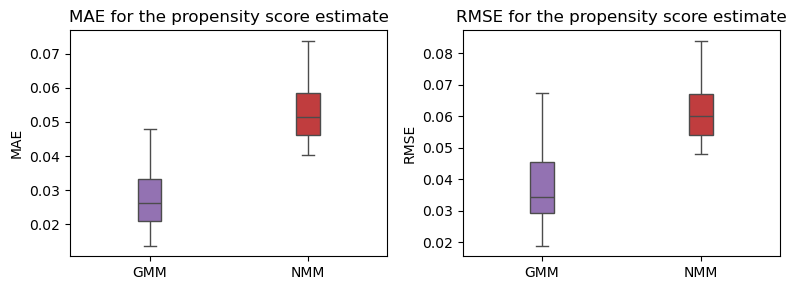

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

# Left subplot: compare MAE
sns.boxplot(data=results[:, :2], ax=axes[0], width=0.15, palette=['tab:purple', 'tab:red'], showfliers=False)
axes[0].set_xticks([0, 1], labels=["GMM", "NMM"])
axes[0].set_ylabel("MAE")
axes[0].set_title("MAE for the propensity score estimate")
# axes[0].set_ylim(0, 0.15)

# Right subplot: compare RMSE
sns.boxplot(data=results[:, 2:], ax=axes[1], width=0.15, palette=['tab:purple', 'tab:red'], showfliers=False)
axes[1].set_xticks([0, 1], labels=["GMM", "NMM"])
axes[1].set_ylabel("RMSE")
axes[1].set_title("RMSE for the propensity score estimate")
# axes[1].set_ylim(0, 0.25)

plt.tight_layout()

plt.savefig('results/propensity_score1.png',dpi=300,
    bbox_inches="tight",)

plt.show()

Below is part of the code for produing comparison conditional on the value of $X_1$.

In [20]:
X1s = [-0.5, 0, 0.5]

In [21]:
colors = ["#0072B2", "#009E73", "#3ECBD7", "#D55E00"]
markers = ["o", "*", "s", "x"]
labels = ["Truth", "GMM-MAR", "GMM-MAR-normalized-by-W", 'NMM']

legend_handles = [
    Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle="None",
        markersize=8,
        label=label
    )
    for color, marker, label in zip(colors, markers, labels)
]
# fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# fig.legend(handles=legend_handles, loc="upper center", ncol=3)
# plt.show()

In [23]:
ntest = 2000


def compute_propensity_scores(pse, X1s, ntest):
    """Compute all propensity score estimates for each fixed value of X1."""
    results = []
    for x1 in X1s:
        X1test = x1 * torch.ones(ntest)
        X2test = pse._conditional(X1test)
        Xtest = torch.stack([X1test, X2test], dim=1)

        results.append({
            "x1": x1,
            "x2": X2test,
            "gmm": pse.estimate_propensity_score_gmm(Xtest),
            # "gmm_mar": pse.estimate_propensity_score_gmm_mar(Xtest),
            "nmm": pse.estimate_propensity_score_nmm(Xtest, fast=False),  # fast=False: compute on a test set
            "true": pse.true_score_motivating_example_mar(Xtest),
        })
    return results


pse_x1 = MotivatingExamplePSE(d=2)
results2 = compute_propensity_scores(pse_x1, X1s, ntest)

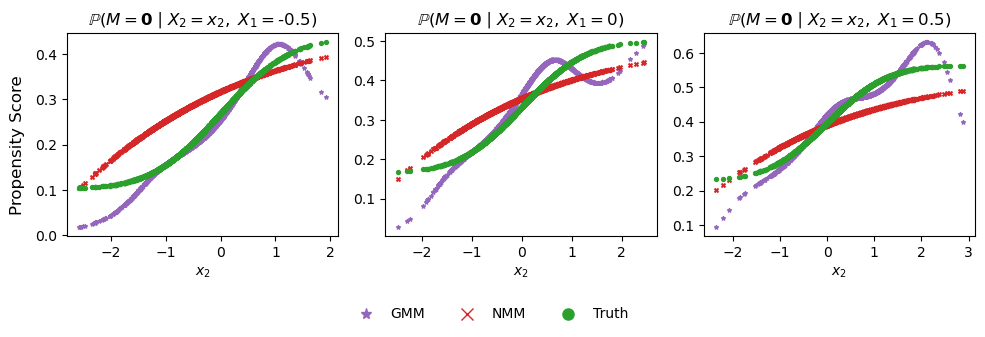

In [42]:
STYLES = {
    "gmm":  dict(label="GMM",  marker="*", color="tab:purple"),
    # "gmm_mar": dict(label="GMM (MAR)", marker="x", color="#3ECBD7"),
    "nmm":  dict(label="NMM",  marker="x", color="tab:red"),
    "true": dict(label="Truth", marker="o", color="tab:green"),
}


def make_legend_handles(styles=STYLES, markersize=8):
    return [
        Line2D([0], [0], linestyle="None", markersize=markersize,
               marker=s["marker"], color=s["color"], label=s["label"])
        for s in styles.values()
    ]


def plot_propensity_scores(results, styles=STYLES, savepath=None):
    fig, axes = plt.subplots(1, len(results), figsize=(10, 3))
    axes = np.atleast_1d(axes)

    for res, ax in zip(results, axes):
        for key, s in styles.items():
            ax.scatter(res["x2"], res[key], marker=s["marker"], c=s["color"], s=8)
        ax.set_title(r'$\mathbb{P} (M = \mathbf{0} \mid X_2 = x_2, \; X_1 = $' + f'{res["x1"]})')
        ax.set_xlabel('$x_2$')

    fig.supylabel('Propensity Score')
    fig.legend(handles=make_legend_handles(styles), loc="upper center",
               ncol=len(styles), bbox_to_anchor=(0.5, 0.0), frameon=False)

    fig.tight_layout()
    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, axes


plot_propensity_scores(results2, savepath='results/propensity_score2.png')
plt.show()

KeyboardInterrupt: 

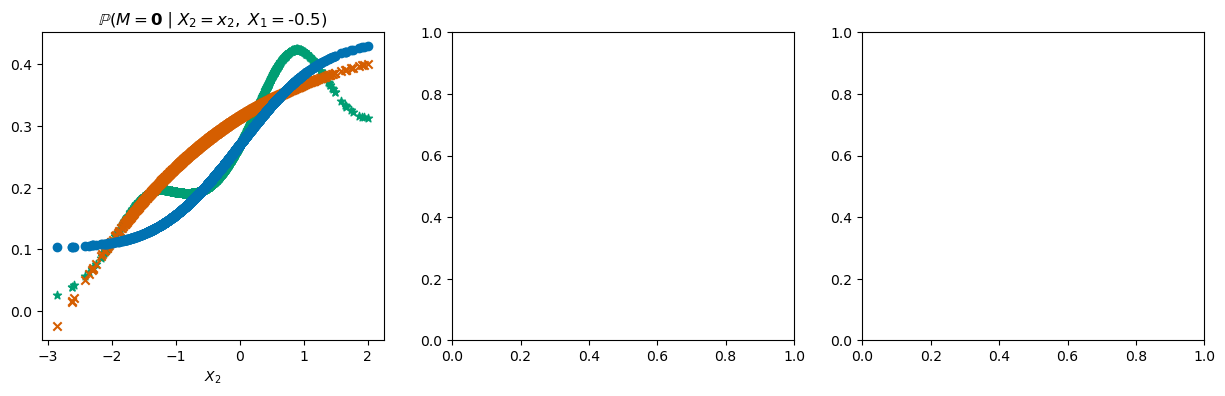

In [22]:
ntest = 2000

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pse_x1 = MotivatingExamplePSE(d=2)

for x1, ax in zip(X1s, axes):
    X1test = x1 * torch.ones(ntest)
    X2test = pse_x1._conditional(X1test)
    Xtest = torch.stack([X1test, X2test], dim=1)
    ax.scatter(X2test, pse_x1.estimate_propensity_score_gmm(Xtest), marker='*', c="#009E73")
    # ax.scatter(X2test, pse_x1.estimate_propensity_score_gmm_mar(Xtest), marker='x', c="#3ECBD7")
    ax.scatter(X2test, pse_x1.estimate_propensity_score_nmm(Xtest, fast=False), marker='x', c="#D55E00") # set fast to false to calculate on a test set
    ax.scatter(X2test, pse_x1.true_score_motivating_example_mar(Xtest), marker='o', c="#0072B2")
    ax.set_title(r'$\mathbb{P} (M = \mathbf{0} \mid X_2 = x_2, \; X_1 = $' + f'{x1})')
    ax.set_xlabel('$X_2$')

fig.supylabel('Propensity Score')
fig.legend(handles=legend_handles, loc="upper center", ncol=4, 
    bbox_to_anchor=(0.5, -0.05),)

plt.tight_layout()
plt.savefig('results/propensity_score2.png',dpi=300,
    bbox_inches="tight",)

plt.show()